In [1]:
import torch
import torch.nn as nn
import numpy as np
import h5py
import matplotlib.pyplot as plt
import sys
sys.path.append('../')
from src.optics_alignment_regression.model import OpticsAlignmentRegressionModel
from src.optics_alignment_regression.train import train_model

In [2]:
optics_alignment_model = OpticsAlignmentRegressionModel(output_dim=2, input_dim=(1, 86, 81))
print(optics_alignment_model)

OpticsAlignmentRegressionModel(
  (CNN_model): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
  )
  (regressor): Sequential(
    (0): Linear(in_features=7744, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [3]:
toy_data = np.random.rand(100, 1, 86, 81).astype(np.float32)

output = optics_alignment_model.forward(torch.from_numpy(toy_data))

print("Output shape:", output.shape)  # Should be (100, 2)

Output shape: torch.Size([100, 2])


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [9]:
from src.optics_alignment_regression.dataset import load_split_h5

data_path = '../data/split_dataset.h5'
train_data = load_split_h5(data_path, 'train')
print(f"Train data shape: {train_data[0].shape}, Train labels shape: {train_data[1].shape}")

Train data shape: (48884, 86, 81), Train labels shape: (48884, 2)


In [11]:
train_val_loss_history_path = "../outputs/train_val_loss_history.npz"
train_hist = np.load(train_val_loss_history_path)['train_loss']
val_hist = np.load(train_val_loss_history_path)['val_loss']

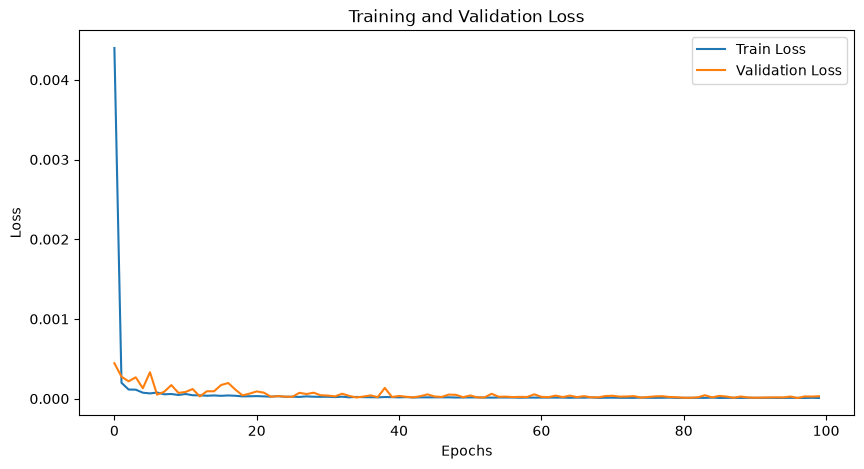

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(train_hist, label='Train Loss')
plt.plot(val_hist, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig("../outputs/train_valid_loss.png", dpi=150)

In [13]:
test_predictions_path = "../outputs/evaluation_results.npz"
evaluation_results = np.load(test_predictions_path)
test_predictions = evaluation_results['predictions']
target_values = evaluation_results['targets']

In [15]:
print(f"Test predictions shape: {test_predictions.shape}, Target values shape: {target_values.shape}")

Test predictions shape: (12221, 2), Target values shape: (12221, 2)


In [16]:
x_preds, z_preds = test_predictions[:, 0], test_predictions[:, 1]
x_true, z_true = target_values[:, 0], target_values[:, 1]

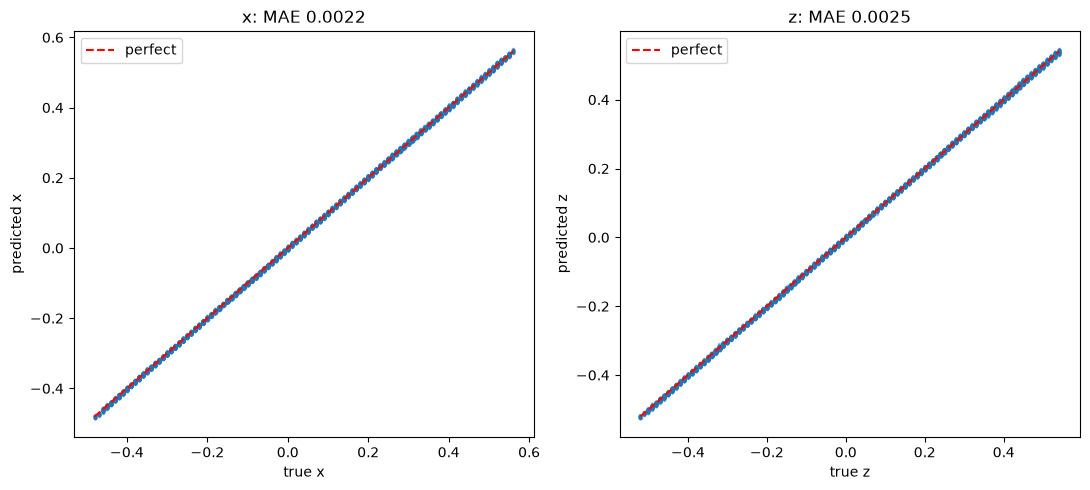

In [18]:
x_preds, z_preds = test_predictions[:, 0], test_predictions[:, 1]
x_true,  z_true  = target_values[:, 0],    target_values[:, 1]

fig, axs = plt.subplots(1, 2, figsize=(11, 5))

for ax, true, pred, name in [(axs[0], x_true, x_preds, "x"),
                             (axs[1], z_true, z_preds, "z")]:
    ax.scatter(true, pred, s=3, alpha=0.3)
    lim = [true.min(), true.max()]
    ax.plot(lim, lim, "r--", label="perfect")
    ax.set_xlabel(f"true {name}")
    ax.set_ylabel(f"predicted {name}")
    ax.set_title(f"{name}: MAE {abs(pred - true).mean():.4f}")
    ax.legend()

plt.tight_layout()
plt.savefig("../outputs/true_vs_pred_xz.png", dpi=150)
plt.show()